# Stronger adaptive attack on the best defense (plus two cheap rigor checks)

**Main question:** does the **global-tile resize-pad** defense (clean cost 1%, adaptive attack 10% on 100 images) survive a stronger attacker?

The adaptive attack in notebook 05 was a lower bound: 3 epochs, one random draw per step, and an *approximation* of SmolVLM's tiling (bicubic instead of the processor's own resizing). This attacker is stronger in three ways:
1. **Exact forward pass:** every step runs the perturbed image through the **real processor** (8-bit rounding, real resizing, real tile cutting). Gradients flow through the bicubic approximation ("straight-through", the standard BPDA technique), so the attacker optimises what the deployed model actually sees.
2. **Averaging over random draws:** 2 random resize-pad draws of the global tile per step (EOT).
3. **More training:** up to 6 epochs, warm-started from the weak adaptive v.

**Evaluation:** 200 held-out images (twice the earlier 100), splitting on, every caption saved, 95% confidence intervals on every rate.

**Two cheap rigor checks included:** confidence intervals everywhere, and a visibility check on the **flattest** region found automatically (not a hand-picked textured crop).

**Resumable:** v is saved after every epoch; a rerun continues where it stopped. Set `STOP_AFTER_EPOCHS` lower if compute is short; evaluation uses the latest saved epoch.
**Rough estimate:** the notebook prints the time per epoch after epoch 1. Expect roughly 1.5–2.5 h in total.
**Outputs:** the emulation check (section 4), the training log (section 5), the results table (section 7) and the figures, saved to `strong_adaptive_results.json`, `strong_adaptive.png` and `visibility_flat_region.png`.

## 1. Configuration

In [1]:
MODEL_ID   = "HuggingFaceTB/SmolVLM-256M-Instruct"
IMG_SIZE   = 512
N_BUILD    = 500
N_EVAL     = 200                     # twice the earlier 100
OUT_DIR    = "/content/drive/MyDrive/uap_smolvlm"
XI         = 10/255
V10_PATH   = OUT_DIR + "/uap_smolvlm256m_linf10.npy"
WEAK_PATH  = OUT_DIR + "/adaptive_v10_global_tile__resize_pad.npy"
CKPT_PATH  = OUT_DIR + "/strong_adaptive_globalrrp_ckpt.pt"
STRONG_PATH= OUT_DIR + "/strong_adaptive_v10_global_tile_resize_pad.npy"
STRONG_EPOCHS     = 6
STOP_AFTER_EPOCHS = 6               # lower this to stop early (e.g. 3) if compute is short
EOT_DRAWS  = 2                      # random global-tile draws averaged per step
LOCAL_TILES_PER_STEP = 3
BATCH      = 4
RRP_MIN    = 0.8
CAPTION_SIM_CHANGED = 0.5
MAX_NEW_TOKENS = 40
P_DESCRIBE = "Describe this image in one sentence."
SEED = 0

## 2. Setup, data, model

In [2]:
!pip -q install "transformers>=4.50" sentence-transformers
import time, json, glob, random, tarfile, math
from pathlib import Path
import numpy as np, torch, torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image
from torchvision import transforms
from tqdm.auto import tqdm
from google.colab import drive
drive.mount("/content/drive")
DEVICE = "cuda"; assert torch.cuda.is_available(), "Runtime -> Change runtime type -> T4 GPU"
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
OUT = Path(OUT_DIR)

DATA_DIR = Path("/content/data"); DATA_DIR.mkdir(exist_ok=True)
TAR = DATA_DIR / "imagenetv2-matched-frequency.tar.gz"
if not list(DATA_DIR.glob("imagenetv2-*/")):
    !wget -q --show-progress -O {TAR} https://huggingface.co/datasets/vaishaal/ImageNetV2/resolve/main/imagenetv2-matched-frequency.tar.gz
    with tarfile.open(TAR, "r:*") as t: t.extractall(DATA_DIR)
    TAR.unlink()
FILES = sorted(glob.glob(str(DATA_DIR / "imagenetv2-*" / "*" / "*.jpeg")))
perm = np.random.RandomState(SEED).permutation(len(FILES))
PREPROC = transforms.Compose([transforms.Resize(IMG_SIZE), transforms.CenterCrop(IMG_SIZE), transforms.PILToTensor()])
load = lambda fs: torch.stack([PREPROC(Image.open(f).convert("RGB")) for f in tqdm(fs, desc="decoding")])
B_u8 = load([FILES[i] for i in perm[:N_BUILD]])
E_u8 = load([FILES[i] for i in perm[N_BUILD:N_BUILD + N_EVAL]])

from transformers import AutoProcessor, AutoModelForImageTextToText
processor = AutoProcessor.from_pretrained(MODEL_ID); processor.tokenizer.padding_side = "left"
model = AutoModelForImageTextToText.from_pretrained(MODEL_ID, torch_dtype=torch.float32).to(DEVICE).eval()
for p in model.parameters(): p.requires_grad_(False)
VIS = model.model.vision_model
ip = processor.image_processor
print("image processor class:", type(ip).__name__)
MEAN = torch.tensor(ip.image_mean, device=DEVICE).view(1, 3, 1, 1)
STD  = torch.tensor(ip.image_std,  device=DEVICE).view(1, 3, 1, 1)

V10  = torch.from_numpy(np.load(V10_PATH).copy()).float()
WEAK = torch.from_numpy(np.load(WEAK_PATH).copy()).float()

from sentence_transformers import SentenceTransformer
st = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2", device=DEVICE)
def text_sim(a, b):
    ea = st.encode(a, convert_to_tensor=True, normalize_embeddings=True)
    eb = st.encode(b, convert_to_tensor=True, normalize_embeddings=True)
    return (ea * eb).sum(-1).cpu()
def changed_flags(a, b): return (text_sim(a, b) < CAPTION_SIM_CHANGED).numpy()
def wilson(k, n, z=1.96):
    p = k / n; d = 1 + z * z / n; c = (p + z * z / (2 * n)) / d
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return c - h, c + h

Mounted at /content/drive
/content/data/image 100%[===================>]   1.18G   118MB/s    in 10s     


/tmp/ipykernel_544/2618952784.py:19: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  with tarfile.open(TAR, "r:*") as t: t.extractall(DATA_DIR)


decoding:   0%|          | 0/500 [00:00<?, ?it/s]

decoding:   0%|          | 0/200 [00:00<?, ?it/s]

processor_config.json:   0%|          | 0.00/68.0 [00:00<?, ?B/s]

chat_template.json:   0%|          | 0.00/429 [00:00<?, ?B/s]

... (23 outputs left out)

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

## 3. Real pipeline pieces and their differentiable approximations

In [3]:
GRAY = (128, 128, 128)
def to01(u8): return u8.to(DEVICE).float().div(255)
def norm(x01): return (x01 - MEAN) / STD
def token_cosine(a, b): return F.cosine_similarity(a, b, dim=-1).mean(dim=1)
def u8_to_pil(u8): return Image.fromarray(u8.permute(1, 2, 0).numpy())
def x01_to_pil(x01):  # 8-bit rounding, as when the perturbed image is saved
    return Image.fromarray((x01.detach() * 255).round().clamp(0, 255).byte().permute(1, 2, 0).cpu().numpy())
def to_pil_u8(u8, pert=None):
    x = u8.float()
    if pert is not None: x = x + pert[0] * 255
    return Image.fromarray(x.round().clamp(0, 255).to(torch.uint8).permute(1, 2, 0).numpy())

def rrp_params(rng):
    s = rng.uniform(RRP_MIN, 1.0); size = int(round(IMG_SIZE * s))
    return size, rng.randint(0, IMG_SIZE - size + 1), rng.randint(0, IMG_SIZE - size + 1)
def rrp_pil(p, prm):
    size, oy, ox = prm
    c = Image.new("RGB", (IMG_SIZE, IMG_SIZE), GRAY); c.paste(p.resize((size, size), Image.BILINEAR), (ox, oy)); return c
def rrp_t(x, prm):
    size, oy, ox = prm
    out = torch.full_like(x, 0.5)
    out[..., oy:oy+size, ox:ox+size] = F.interpolate(x, size=(size, size), mode="bilinear", antialias=True, align_corners=False)
    return out

# ---- REAL processor (exact, not differentiable): normalised tiles ----
def real_split(pils):            # (B, 17, 3, 512, 512): 16 local tiles (row-major) + global tile last
    px = ip(images=[[p] for p in pils], do_image_splitting=True, return_tensors="pt")["pixel_values"]
    assert px.shape[1] == 17, f"expected 17 tiles, got {px.shape[1]}"
    return px.to(DEVICE)
def real_single(pils):           # (B, 3, 512, 512): one tile, splitting off
    return ip(images=[[p] for p in pils], do_image_splitting=False, return_tensors="pt")["pixel_values"][:, 0].to(DEVICE)

# ---- APPROXIMATION (differentiable): used only for gradients ----
def approx_local(x01):           # (B, 16, 3, 512, 512), normalised
    B = x01.shape[0]
    big = F.interpolate(x01, size=4 * IMG_SIZE, mode="bicubic", align_corners=False).clamp(0, 1)
    t = big.unfold(2, IMG_SIZE, IMG_SIZE).unfold(3, IMG_SIZE, IMG_SIZE).permute(0, 2, 3, 1, 4, 5)
    return norm(t.reshape(-1, 3, IMG_SIZE, IMG_SIZE)).reshape(B, 16, 3, IMG_SIZE, IMG_SIZE)

def straight_through(approx, real):   # forward = real, backward = d(approx)
    return approx + (real - approx).detach()

## 4. Emulation check: how close is the approximation to the real processor?

In [4]:
with torch.no_grad():
    x = to01(E_u8[:3]); pils = [u8_to_pil(u) for u in E_u8[:3]]
    real = real_split(pils); appr = approx_local(x)
    # tile order: for image 0, each approximate tile should be closest to the real tile with the same index
    mse = ((appr[0][:, None] - real[0, :16][None]) ** 2).mean(dim=(2, 3, 4))      # (16 approx, 16 real)
    order_ok = bool((mse.argmin(dim=1).cpu() == torch.arange(16)).all())
    pix_gap = (appr - real[:, :16]).abs().mean().item()
    za = VIS(pixel_values=appr.reshape(-1, 3, IMG_SIZE, IMG_SIZE)[:8]).last_hidden_state
    zr = VIS(pixel_values=real[:, :16].reshape(-1, 3, IMG_SIZE, IMG_SIZE)[:8]).last_hidden_state
    feat_cos = token_cosine(za, zr).mean().item()
print(f"tile order matches: {order_ok}")
print(f"mean |approx - real| on normalised local tiles: {pix_gap:.4f}  (normalised range is about [-1, 1])")
print(f"visual-token cosine, approx vs real clean tiles: {feat_cos:.4f}  (1.0 = identical features)")
assert order_ok, "Tile order differs from the emulation: fix this before training."

tile order matches: True
mean |approx - real| on normalised local tiles: 0.0038  (normalised range is about [-1, 1])
visual-token cosine, approx vs real clean tiles: 0.9975  (1.0 = identical features)


## 5. Train the strong adaptive perturbation (resumable, saved every epoch)

In [ ]:
def strong_step(x, v, pils_c, rng):
    # Computes the loss in pieces and back-propagates each piece separately (keeps GPU memory low).
    # Loss = 0.5 * local-tile cosine + 0.5 * mean over EOT draws of the defended global-tile cosine.
    xa0 = (x + v).clamp(0, 1)
    pils_a = [x01_to_pil(t) for t in xa0]
    # (a) local tiles: exact forward through the real processor, gradient through the approximation
    sel = torch.as_tensor(rng.choice(16, LOCAL_TILES_PER_STEP, replace=False))
    with torch.no_grad():
        real_c = real_split(pils_c)[:, sel]; real_a = real_split(pils_a)[:, sel]
        z0 = VIS(pixel_values=real_c.reshape(-1, 3, IMG_SIZE, IMG_SIZE)).last_hidden_state
    a_loc = straight_through(approx_local((x + v).clamp(0, 1))[:, sel], real_a)
    loc = token_cosine(z0, VIS(pixel_values=a_loc.reshape(-1, 3, IMG_SIZE, IMG_SIZE)).last_hidden_state).mean()
    (0.5 * loc).backward()
    # (b) defended global tile, averaged over EOT_DRAWS random resize-pad draws
    glob_ = 0.0
    for _ in range(EOT_DRAWS):
        prm = rrp_params(rng)
        with torch.no_grad():
            rc = real_single([rrp_pil(p, prm) for p in pils_c]); ra = real_single([rrp_pil(p, prm) for p in pils_a])
            z0 = VIS(pixel_values=rc).last_hidden_state
        a_g = straight_through(norm(rrp_t((x + v).clamp(0, 1), prm)), ra)
        g = token_cosine(z0, VIS(pixel_values=a_g).last_hidden_state).mean() / EOT_DRAWS
        (0.5 * g).backward(); glob_ += g.item()
    return 0.5 * loc.item() + 0.5 * glob_, loc.item(), glob_

if Path(CKPT_PATH).exists():
    ck = torch.load(CKPT_PATH, weights_only=False); v = ck["v"].to(DEVICE); start = ck["epoch"]; print(f"Resuming after epoch {start}")
else:
    v = WEAK.clone().to(DEVICE); start = 0; print("Starting from the weak adaptive v")
v.requires_grad_(True)
opt = torch.optim.Adam([v], lr=XI / 10)
if Path(CKPT_PATH).exists() and "opt" in ck: opt.load_state_dict(ck["opt"])
rng = np.random.RandomState(SEED + start)
for ep in range(start, min(STRONG_EPOCHS, STOP_AFTER_EPOCHS)):
    t0 = time.time(); L, LL, LG = [], [], []
    for idx in tqdm(torch.randperm(len(B_u8), generator=torch.Generator().manual_seed(SEED + ep)).split(BATCH), desc=f"epoch {ep+1}", leave=False):
        x = to01(B_u8[idx])
        opt.zero_grad()
        loss, l_loc, l_glob = strong_step(x, v, [u8_to_pil(B_u8[i]) for i in idx], rng)
        opt.step()
        with torch.no_grad(): v.clamp_(-XI, XI)
        L.append(loss); LL.append(l_loc); LG.append(l_glob)
    torch.save({"v": v.detach().cpu(), "epoch": ep + 1, "opt": opt.state_dict()}, CKPT_PATH)
    print(f"epoch {ep+1}/{STRONG_EPOCHS}: loss {np.mean(L):.3f} | local-tile cosine {np.mean(LL):.3f} | "
          f"defended global-tile cosine {np.mean(LG):.3f} | {(time.time()-t0)/60:.1f} min (saved)")
STRONG = torch.load(CKPT_PATH, weights_only=False)["v"].float()
np.save(STRONG_PATH, STRONG.numpy())
print("Strong adaptive v from epoch", torch.load(CKPT_PATH, weights_only=False)["epoch"], "| ||v||_inf =", round(STRONG.abs().max().item() * 255, 2), "/255")

Resuming after epoch 6


epoch 7:   0%|          | 0/125 [00:00<?, ?it/s]

epoch 7/10: loss 0.458 | local-tile cosine 0.272 | defended global-tile cosine 0.645 | 6.9 min (saved)


epoch 8:   0%|          | 0/125 [00:00<?, ?it/s]

epoch 8/10: loss 0.453 | local-tile cosine 0.265 | defended global-tile cosine 0.640 | 6.9 min (saved)


epoch 9:   0%|          | 0/125 [00:00<?, ?it/s]

epoch 9/10: loss 0.457 | local-tile cosine 0.273 | defended global-tile cosine 0.641 | 6.9 min (saved)


epoch 10:   0%|          | 0/125 [00:00<?, ?it/s]

epoch 10/10: loss 0.451 | local-tile cosine 0.261 | defended global-tile cosine 0.641 | 6.9 min (saved)
Strong adaptive v from epoch 10 | ||v||_inf = 10.0 /255


## 6. Evaluate on 200 images (splitting on; every caption saved)

In [ ]:
def chat(prompt):
    msgs = [{"role": "user", "content": [{"type": "image"}, {"type": "text", "text": prompt}]}]
    return processor.apply_chat_template(msgs, add_generation_prompt=True)

@torch.no_grad()
def gen(u8s, pert, defended, bs=8):
    rng = np.random.RandomState(SEED)          # same random draws for every condition
    outs = []
    for i in range(0, len(u8s), bs):
        pils = [to_pil_u8(u, pert) for u in u8s[i:i+bs]]
        inp = processor(text=[chat(P_DESCRIBE)] * len(pils), images=[[p] for p in pils],
                        do_image_splitting=True, return_tensors="pt", padding=True)
        if defended:
            for j, p in enumerate(pils):
                inp["pixel_values"][j, -1] = ip(images=[[rrp_pil(p, rrp_params(rng))]], do_image_splitting=False,
                                                return_tensors="pt")["pixel_values"][0, 0]
        inp = inp.to(DEVICE)
        g = model.generate(**inp, max_new_tokens=MAX_NEW_TOKENS, do_sample=False)
        outs += processor.batch_decode(g[:, inp["input_ids"].shape[1]:], skip_special_tokens=True)
    return [o.strip() for o in outs]

RPATH = OUT / "strong_adaptive_results.json"
CAPS = json.load(open(RPATH))["captions"] if RPATH.exists() else {}
plan = [("clean", None, False), ("clean, defended", None, True),
        ("fixed v, no defense", V10, False), ("fixed v, defended", V10, True),
        ("weak adaptive v, defended", WEAK, True), ("strong adaptive v, defended", STRONG, True),
        ("strong adaptive v, no defense", STRONG, False)]
t0 = time.time()
for name, pert, dfd in plan:
    if name in CAPS: print(f"{name}: already done"); continue
    CAPS[name] = gen(E_u8, pert, dfd)
    json.dump({"captions": CAPS}, open(RPATH, "w"), indent=1)
    print(f"{name}: done ({(time.time()-t0)/60:.1f} min)")

clean: already done
clean, defended: already done
fixed v, no defense: already done
fixed v, defended: already done
weak adaptive v, defended: already done
strong adaptive v, defended: already done
strong adaptive v, no defense: already done


## 7. Results with 95% confidence intervals

In [ ]:
rows = [("clean cost of the defense", "clean", "clean, defended"),
        ("fixed v, no defense", "clean", "fixed v, no defense"),
        ("fixed v, defended", "clean, defended", "fixed v, defended"),
        ("weak adaptive v, defended", "clean, defended", "weak adaptive v, defended"),
        ("STRONG adaptive v, defended", "clean, defended", "strong adaptive v, defended"),
        ("strong adaptive v, no defense", "clean", "strong adaptive v, no defense")]
RES = {}
print(f"{N_EVAL} held-out images, splitting on, real pipeline. Captions changed vs the matching clean reference.\n")
print(f"{'condition':34s}{'changed':>9s}{'95% CI':>18s}")
print("-" * 61)
for label, ref, cond in rows:
    f = changed_flags(CAPS[ref], CAPS[cond]); k, n = int(f.sum()), len(f); lo, hi = wilson(k, n)
    RES[label] = {"k": k, "n": n, "rate": k / n, "ci95": [lo, hi]}
    print(f"{label:34s}{k/n:>9.1%}{f'[{lo:.1%}, {hi:.1%}]':>18s}")
w, s = changed_flags(CAPS["clean, defended"], CAPS["weak adaptive v, defended"]), changed_flags(CAPS["clean, defended"], CAPS["strong adaptive v, defended"])
print(f"\nPaired, same images: strong breaks {int((s & ~w).sum())} captions the weak one did not; weak breaks {int((w & ~s).sum())} the strong one did not.")
json.dump({"captions": CAPS, "results": RES}, open(RPATH, "w"), indent=1)

print("\nExamples (clean, defended -> strong adaptive v, defended):")
for c0, c1 in list(zip(CAPS["clean, defended"], CAPS["strong adaptive v, defended"]))[:6]:
    print(f"   {c0[:60]:60s} -> {c1[:60]}")

200 held-out images, splitting on, real pipeline. Captions changed vs the matching clean reference.

condition                           changed            95% CI
-------------------------------------------------------------
clean cost of the defense              2.5%      [1.1%, 5.7%]
fixed v, no defense                   60.5%    [53.6%, 67.0%]
fixed v, defended                      1.5%      [0.5%, 4.3%]
weak adaptive v, defended             13.0%     [9.0%, 18.4%]
STRONG adaptive v, defended           30.5%    [24.5%, 37.2%]
strong adaptive v, no defense         32.5%    [26.4%, 39.3%]

Paired, same images: strong breaks 38 captions the weak one did not; weak breaks 3 the strong one did not.

Examples (clean, defended -> strong adaptive v, defended):
   In this image we can see a bird on the branch of a tree.     -> In this image, we can see a bird on the branch of a tree. We
   In this image we can see two dogs standing on the ground.    -> In this image we can see two dogs on the

## 8. Figures: results with error bars, and visibility on the flattest region

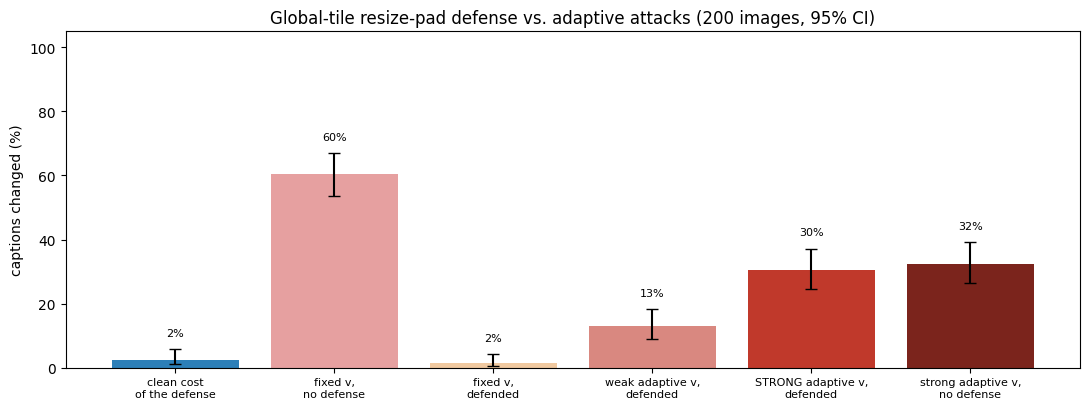

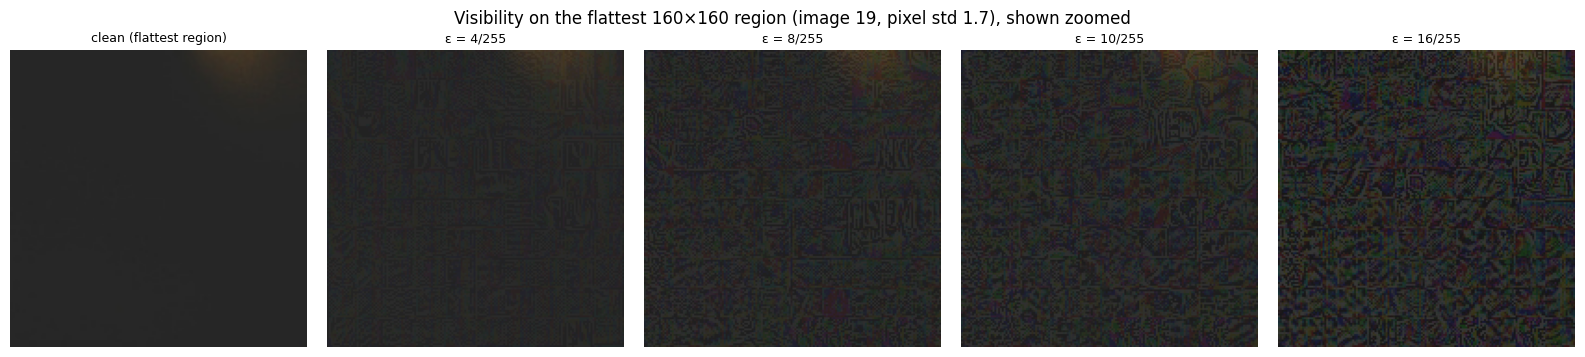

In [ ]:
labels = list(RES); vals = [100 * RES[l]["rate"] for l in labels]
err = np.array([[100 * (RES[l]["rate"] - RES[l]["ci95"][0]), 100 * (RES[l]["ci95"][1] - RES[l]["rate"])] for l in labels]).T
cols = ["#2c7fb8", "#e6a0a0", "#f0c9a0", "#d98880", "#c0392b", "#7b241c"]
fig, ax = plt.subplots(figsize=(11, 4.2))
b = ax.bar(range(len(labels)), vals, yerr=err, capsize=4, color=cols); ax.bar_label(b, fmt="%.0f%%", padding=8, fontsize=8)
ax.set_xticks(range(len(labels)), [l.replace(", ", ",\n").replace(" of the", "\nof the") for l in labels], fontsize=8)
ax.set_ylim(0, 105); ax.set_ylabel("captions changed (%)")
ax.set_title(f"Global-tile resize-pad defense vs. adaptive attacks ({N_EVAL} images, 95% CI)")
plt.tight_layout(); plt.savefig(OUT / "strong_adaptive.png", dpi=150); plt.show()

# Visibility on the flattest 160x160 region among the first 30 eval images
best = (1e9, 0, 0, 0)
for i in range(30):
    g = E_u8[i].float().mean(0)
    win = g.unfold(0, 160, 32).unfold(1, 160, 32)                  # (ny, nx, 160, 160)
    sd = win.std(dim=(-1, -2)); j = int(sd.argmin()); ny, nx = divmod(j, sd.shape[1])
    if sd.flatten()[j] < best[0]: best = (sd.flatten()[j].item(), i, ny * 32, nx * 32)
_, i0, y0, x0 = best
eps_files = {e: OUT / ("uap_smolvlm256m_linf%d.npy" % e) for e in [4, 8, 10, 16]}
fig, ax = plt.subplots(1, 5, figsize=(16, 3.6))
ax[0].imshow(E_u8[i0].permute(1, 2, 0)[y0:y0+160, x0:x0+160]); ax[0].set_title("clean (flattest region)", fontsize=9)
for k, (e, f) in enumerate(eps_files.items()):
    if f.exists():
        ve = torch.from_numpy(np.load(f).copy()).float()
        ax[k+1].imshow(np.asarray(to_pil_u8(E_u8[i0], ve))[y0:y0+160, x0:x0+160])
    ax[k+1].set_title(f"ε = {e}/255", fontsize=9)
for a in ax: a.axis("off")
plt.suptitle(f"Visibility on the flattest 160×160 region (image {i0}, pixel std {best[0]:.1f}), shown zoomed")
plt.tight_layout(); plt.savefig(OUT / "visibility_flat_region.png", dpi=150); plt.show()